In [8]:
market_data = [
{'Ticker ': 'AAPL ', 'Sector ': 'Technology ', 'Price ': 175.50 , 'MarketCap_B ': 2800.0 ,
'PE_Ratio ': 30.1 , 'DividendYield ': 0.55} ,
{'Ticker ': 'MSFT ', 'Sector ': 'Technology ', 'Price ': 420.20 , 'MarketCap_B ': 3100.0 ,
'PE_Ratio ': 35.5 , 'DividendYield ': 0.70} ,
{'Ticker ': 'JPM ', 'Sector ': 'Finance ', 'Price ': 190.80 , 'MarketCap_B ': 570.0 , 
'PE_Ratio ': 12.5 , 'DividendYield ': 2.30} ,
{'Ticker ': 'VZ', 'Sector ': 'Communication ', 'Price ': 40.10 , 'MarketCap_B ': 170.0 ,
'PE_Ratio ': 8.8, 'DividendYield ': 6.50} ,
{'Ticker ': 'TSLA ', 'Sector ': 'Automotive ', 'Price ': 205.00 , 'MarketCap_B ': 650.0 ,
'PE_Ratio ': 62.0 , 'DividendYield ': 0.00} ,
{'Ticker ': 'SBUX ', 'Sector ': 'Consumer Cyclical ', 'Price ': 95.00 , 'MarketCap_B ':
105.0 , 'PE_Ratio ': 25.4 , 'DividendYield ': 2.10} ,
{'Ticker ': 'HD', 'Sector ': 'Consumer Cyclical ', 'Price ': 350.00 , 'MarketCap_B ':
360.0 , 'PE_Ratio ': 21.9 , 'DividendYield ': 2.45} ,
{'Ticker ': 'PFE ', 'Sector ': 'Healthcare ', 'Price ': 28.50 , 'MarketCap_B ': 160.0 , 
'PE_Ratio ': 15.0 , 'DividendYield ': 5.50} ,
{'Ticker ': 'XOM ', 'Sector ': 'Energy ', 'Price ': 115.00 , 'MarketCap_B ': 470.0 , 
'PE_Ratio ': 10.2 , 'DividendYield ': 3.80} ,
{'Ticker ': 'KO', 'Sector ': 'Consumer Defensive ', 'Price ': 63.00 , 'MarketCap_B ':
270.0 , 'PE_Ratio ': 23.5 , 'DividendYield ': 3.10} ,
{'Ticker ': 'GS', 'Sector ': 'Finance ', 'Price ': 400.00 , 'MarketCap_B ': 130.0 , 
'PE_Ratio ': 11.1 , 'DividendYield ': 2.70} ,
{'Ticker ': 'NFLX ', 'Sector ': 'Communication ', 'Price ': 625.00 , 'MarketCap_B ':
265.0 , 'PE_Ratio ': 45.0 , 'DividendYield ': 0.00} ,
{'Ticker ': 'AMZN ', 'Sector ': 'Consumer Cyclical ', 'Price ': 180.00 , 'MarketCap_B ':
1850.0 , 'PE_Ratio ': 40.0 , 'DividendYield ': 0.00} ,
{'Ticker ': 'ORCL ', 'Sector ': 'Technology ', 'Price ': 130.00 , 'MarketCap_B ': 365.0 ,
'PE_Ratio ': 32.2 , 'DividendYield ': 1.40} ,
{'Ticker ': 'WFC ', 'Sector ': 'Finance ', 'Price ': 60.00 , 'MarketCap_B ': 200.0 , 
'PE_Ratio ': 10.5 , 'DividendYield ': 2.90}
]

In [ ]:
print("Herzlich Willkommen zum Stock Screener")
print("Geben sie ihren Filter an ")
filter = input()
part = filter.split();
print(part)

if part[0] + " " in market_data[0]:
    for i in range(0,len(market_data)):
        if market_data[i][part[0] + " "] >= int(part[2]):
            print(market_data[i])
        

AZO
URI


C:\Users\Robin Humberg\AppData\Local\Temp\ipykernel_85016\3081914682.py:24: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  if daten[data].diff().last("1ME").mean() > max_difference:
C:\Users\Robin Humberg\AppData\Local\Temp\ipykernel_85016\3081914682.py:25: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  max_difference = daten[data].diff().last("1ME").mean()
C:\Users\Robin Humberg\AppData\Local\Temp\ipykernel_85016\3081914682.py:36: FutureWarning: last is deprecated and will be removed in a future version. Please create a mask and filter using `.loc` instead
  max_difference = daten[data].diff().last("1ME").mean()


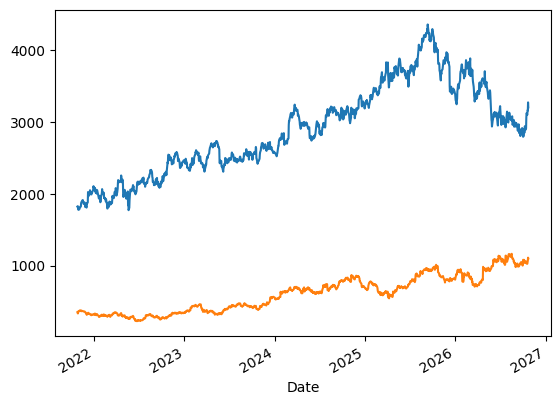

In [2]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import math

#url = "https://raw.githubusercontent.com/datasets/s-and-p-500-companies/master/data/constituents.csv"
#df = pd.read_csv(url)
#aktien = df["Symbol"].str.replace(".","-", regex = False).tolist()
#df.to_csv("sp500.csv", index=False)

#aktien = pd.read_csv("sp500.csv")["Symbol"].tolist()

#daten = yf.download(aktien,period="5y")["Close"]
#daten.to_csv("aktien_daten.csv")

daten = pd.read_csv(
    "aktien_daten.csv",
    index_col=0,
    parse_dates=True
)
max_Ticker = ""
max_difference = -math.inf
for data in daten.columns:
    if daten[data].diff().last("1ME").mean() > max_difference:
        max_difference = daten[data].diff().last("1ME").mean()
        max_Ticker = data

print(max_Ticker)
daten[max_Ticker].plot()

max_difference = -math.inf
max_Ticker = ""

for data in daten.columns:
    if daten[data].diff().iloc[-7:].mean() > max_difference:
        max_difference = daten[data].diff().last("1ME").mean()
        max_Ticker = data

print(max_Ticker)
daten[max_Ticker].plot()

plt.show()

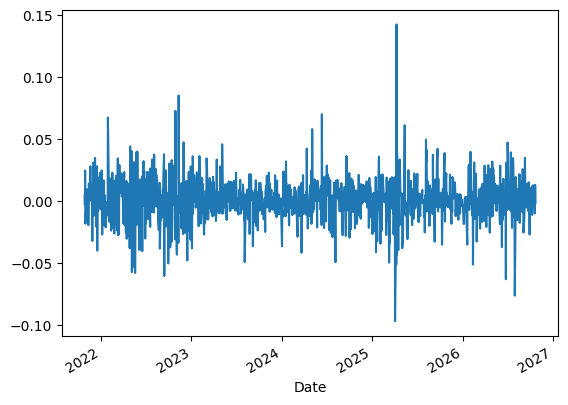

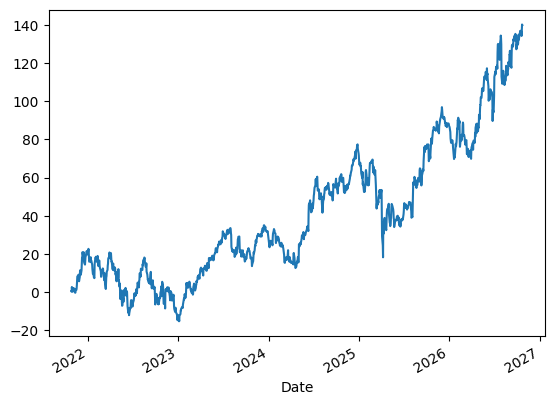

In [3]:
import numpy as np

log_returns = np.log(daten["AAPL"] / daten["AAPL"].shift(1))
log_returns.plot()
plt.show()

returns = (np.exp(log_returns.cumsum()) - 1) * 100
returns.plot()

plt.show()

In [38]:
def evaluate_strategy(returns,risk_free_rate = 0.025):
    returns = returns.dropna()

    equity = (1+returns).cumprod()
    years = len(returns) /252

    drawdown = equity /equity.cummax() -1

    sharpe = (returns.mean() - risk_free_rate / 252) / returns.std() * np.sqrt(252)

    return {
        "Total Return (%)" : (equity.iloc[-1] -1) * 100,
        "CAGR (%)" : (equity.iloc[-1] ** (1/years) -1) * 100,
        "Sharpe Ratio" : sharpe,
        "Volatility (%)" : returns.std() * np.sqrt(252) * 100,
        "Max Drawdown (%)" : drawdown.min() * 100
    }

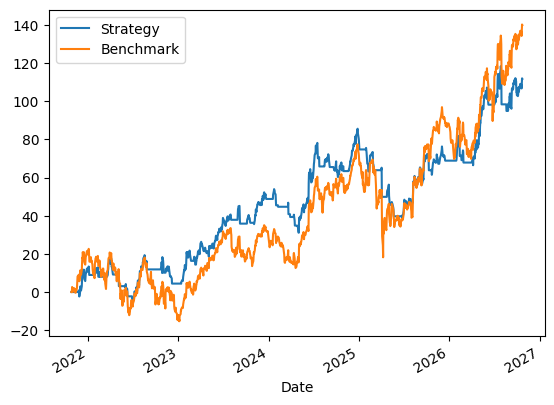

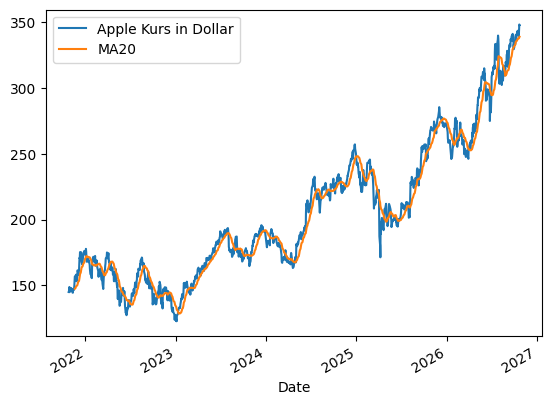

Strategy Metrics: 
Total Return (%)    111.68
CAGR (%)             16.26
Sharpe Ratio          0.89
Volatility (%)       18.67
Max Drawdown (%)    -24.99
Benchmark Metrics: 
Total Return (%)    139.85
CAGR (%)             19.22
Sharpe Ratio          0.76
Volatility (%)       28.03
Max Drawdown (%)    -33.36


In [5]:
prices = daten["AAPL"]

ma = prices.rolling(20).mean()
signal = (prices > ma).astype(int)

strategy_returns = signal.shift(1) * prices.pct_change()

performance = ((1+strategy_returns.fillna(0)).cumprod() -1) *100

benchmark_returns = prices.pct_change()
benchmark = (prices / prices.iloc[0] -1) * 100

metrics = evaluate_strategy(strategy_returns)
benchmark_metrics = evaluate_strategy(benchmark_returns)

performance.plot(label = "Strategy")
benchmark.plot(label = "Benchmark")

plt.legend()
plt.show()

prices.plot(label = "Apple Kurs in Dollar")
ma.plot(label = "MA20")

plt.legend()
plt.show()

print("Strategy Metrics: ")
print(pd.Series(metrics).round(2).to_string())
print("Benchmark Metrics: ")
print(pd.Series(benchmark_metrics).round(2).to_string())

In [31]:
def mean_reversion_strategy(prices,window = 20, threshold = 2.5, trend_window = 100):
    ma = prices.rolling(window).mean()
    std = prices.rolling(window).std()

    trend_ma = prices.rolling(trend_window).mean()
    up_trend = prices > trend_ma

    z_score = (prices - ma) / std

    position = 0
    positions = []

    for i in range(len(prices)):
        score = z_score.iloc[i]
        trend = up_trend.iloc[i]

        if pd.isna(score) or pd.isna(trend):
            position = 0
        elif score < -threshold and trend:
            position = 1
        elif score > -0.5 or not trend:
            position = 0

        positions.append(position)

    positions = pd.Series(positions, index=prices.index).shift(1).fillna(0)

    returns = prices.pct_change()

    strategy_returns = positions * returns
    return strategy_returns, positions
        



Total Return (%)    55.18
CAGR (%)             9.23
Sharpe Ratio         0.61
Volatility (%)      16.30
Max Drawdown (%)   -17.47


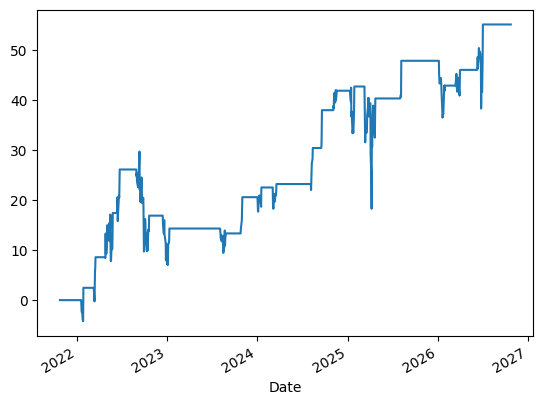

In [7]:
strategy_returns,position = mean_reversion_strategy(prices)

performance = ((1+strategy_returns.fillna(0)).cumprod() -1) *100

performance.plot()

metrics = evaluate_strategy(strategy_returns)
print(pd.Series(metrics).round(2).to_string())

In [42]:
tickers = [ticker for ticker in daten.columns if ticker != "SPY"]

spy = yf.download("SPY",period="5y", auto_adjust=True)["Close"]

if isinstance(spy,pd.DataFrame):
    spy = spy.iloc[:,0]

start = max(daten.index.min(), spy.index.min())
end = min(daten.index.max(), daten.index.max())

spy = spy.loc[start:end]
benchmark_returns = spy.pct_change().dropna()

results = {}
strategy_returns_all = {}

for ticker in tickers: 
    prices = daten[ticker].loc[start:end].dropna()

    if len(prices) < 50:
        continue

    strategy_returns,position = mean_reversion_strategy(prices)
    strategy_returns_all[ticker] = strategy_returns
    results[ticker] = evaluate_strategy(strategy_returns)

results_df = pd.DataFrame(results).T
results_df = results_df.sort_values("CAGR (%)", ascending = False)

print(results_df.round(2).to_string())

metrics_benchmark = evaluate_strategy(benchmark_returns)
print(pd.Series(metrics_benchmark).round(2).to_string())

[*********************100%***********************]  1 of 1 completed
C:\Users\Robin Humberg\AppData\Local\Temp\ipykernel_85016\4292485233.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  sharpe = (returns.mean() - risk_free_rate / 252) / returns.std() * np.sqrt(252)


       Total Return (%)  CAGR (%)  Sharpe Ratio  Volatility (%)  Max Drawdown (%)
SMCI              33.18      5.93          0.54            6.46             -1.93
NVDA              32.36      5.80          0.51            6.62             -3.33
HAL               25.76      4.71          0.43            5.15             -0.58
ISRG              24.20      4.45          0.38            5.20             -3.32
SLB               22.60      4.18          0.27            6.67             -9.08
MU                22.37      4.14          0.21            9.56             -5.90
DASH              21.82      4.05          0.34            4.60             -3.16
APP               20.94      3.89          0.31            4.60             -2.59
GS                20.03      3.74          0.43            2.82             -0.52
MRNA              19.63      3.67          0.16            8.80              0.00
PLTR              18.35      3.44          0.16            6.97             -2.63
JCI             

C:\Users\Robin Humberg\AppData\Local\Temp\ipykernel_85016\585185379.py:1: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns_all = daten.pct_change()


0 bps -> 7.4
5 bps -> 5.21
10 bps -> 3.07
20 bps -> -1.09


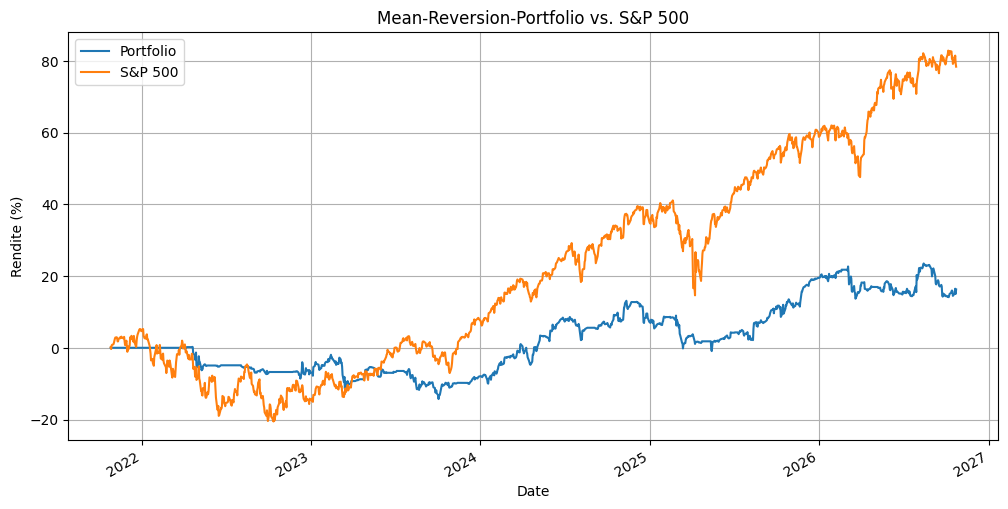

Portfolio:
Total Return (%)    16.24
CAGR (%)             3.07
Sharpe Ratio         0.10
Volatility (%)      10.05
Max Drawdown (%)   -14.50
Benchmark: 
Total Return (%)    78.36
CAGR (%)            12.33
Sharpe Ratio         0.62
Volatility (%)      17.15
Max Drawdown (%)   -24.50


In [43]:
returns_all = daten.pct_change()
positions_all = pd.DataFrame(0.0,index=daten.index,columns=daten.columns)

for ticker in daten.columns:
    prices = daten[ticker].dropna()

    _,position = mean_reversion_strategy(prices)

    positions_all.loc[position.index,ticker] = position

positions_all = positions_all.fillna(0)

N = 10

active_count = positions_all.sum(axis=1)

active_count = active_count.replace(0, np.nan)

weights = positions_all.div(np.maximum(active_count,N), axis = 0).fillna(0)

position_changes = positions_all.diff().abs()


cost_rate = 0.001

turnover = weights.diff().abs().sum(axis = 1)
turnover.iloc[0] = weights.iloc[0].abs().sum()

daily_costs = turnover * cost_rate

gross_returns = (weights * returns_all).sum(axis = 1)
net_returns = gross_returns - daily_costs

portfolio_performance = ((1+net_returns.fillna(0)).cumprod() -1) *100

for bps in [0, 5, 10, 20]:
    net = gross_returns - turnover * bps / 10_000
    print(bps, "bps ->", round(evaluate_strategy(net)["CAGR (%)"], 2))

benchmark_performance = (
    (1 + benchmark_returns.fillna(0)).cumprod() - 1
) * 100

comparison = pd.concat(
    [portfolio_performance.rename("Portfolio"),
     benchmark_performance.rename("S&P 500")],
    axis=1
).dropna()

comparison.plot(figsize=(12, 6))
plt.title("Mean-Reversion-Portfolio vs. S&P 500")
plt.ylabel("Rendite (%)")
plt.grid(True)
plt.show()

print("Portfolio:")
print(pd.Series(evaluate_strategy(net_returns)).round(2).to_string())
print("Benchmark: ")
print(pd.Series(metrics_benchmark).round(2).to_string())

## Grid Search mit Train/Test-Split

Ziel: herausfinden, ob die Mean-Reversion-Strategie **robuste** Parameter hat, oder ob gute Ergebnisse nur Zufall sind.

- **Parameter:** `window` (Länge des Z-Score-Fensters), `trend_window` (Trendfilter), `threshold` (Einstiegsschwelle in Standardabweichungen) und `SLOTS` (maximale Anzahl gleichzeitiger Positionen, feste Gewichte `1/N`).
- **Split:** Die Parameter werden nur auf den ersten 60 % der Daten (Train) bewertet. Der Rest (Test) wird nie zum Auswählen benutzt, sondern zeigt, ob die Auswahl außerhalb der Stichprobe hält.
- **Kosten:** Alle Ergebnisse sind netto, `COST_BPS` pro Seite auf den Turnover.
- **Warm-up:** Alle Kombinationen werden ab demselben Tag gemessen (nach dem längsten `trend_window`), sonst wären lange Trendfenster im Train-Zeitraum unfair benachteiligt.

In [ ]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

WINDOWS = [10, 20, 30, 40]
TREND_WINDOWS = [50, 100, 150, 200]
THRESHOLDS = [1.5, 2.0, 2.5, 3.0]
SLOTS = [5, 10, 20]
COST_BPS = 5
TRAIN_SHARE = 0.6
EXIT_Z = -0.5
MIN_TURNOVER = 3  # per year; below that the Sharpe rests on a handful of trades

returns_all = daten.pct_change(fill_method=None)

sample = returns_all.index[max(TREND_WINDOWS):]
split_date = sample[int(len(sample) * TRAIN_SHARE)]
train_idx = sample[sample < split_date]
test_idx = sample[sample >= split_date]


def mean_reversion_positions(prices, window, threshold, trend_window, exit_z=EXIT_Z):
    """
    Vectorized version of mean_reversion_strategy for a whole price DataFrame.

    Entry: z-score below -threshold while price is above its trend MA.
    Exit: z-score above exit_z or trend lost. Positions are lagged one day.

    :param prices: DataFrame of close prices (dates x tickers)
    :return: DataFrame of 0/1 positions, already shifted by one day
    """
    ma = prices.rolling(window).mean()
    std = prices.rolling(window).std()
    z_score = (prices - ma) / std
    up_trend = prices > prices.rolling(trend_window).mean()

    # NaN = "no signal today": ffill() carries the last entry/exit state forward
    state = pd.DataFrame(np.nan, index=prices.index, columns=prices.columns)
    state[(z_score > exit_z) | ~up_trend] = 0.0
    state[z_score.isna()] = 0.0
    state[(z_score < -threshold) & up_trend] = 1.0

    return state.ffill().fillna(0.0).shift(1).fillna(0.0)


def portfolio_returns(positions, slots):
    """
    Fixed-slot portfolio: every position gets 1/slots, the rest stays in cash.

    :return: tuple of (gross daily returns, daily turnover)
    """
    weights = positions.div(np.maximum(positions.sum(axis=1), slots), axis=0)
    turnover = weights.diff().abs().sum(axis=1)
    turnover.iloc[0] = weights.iloc[0].abs().sum()
    gross = (weights * returns_all).sum(axis=1)
    return gross, turnover


print(f"Stichprobe: {sample[0].date()} bis {sample[-1].date()}")
print(f"Train: {len(train_idx)} Tage bis {train_idx[-1].date()} | Test: {len(test_idx)} Tage ab {test_idx[0].date()}")
print(f"Kombinationen: {len(WINDOWS) * len(TREND_WINDOWS) * len(THRESHOLDS) * len(SLOTS)}")


In [ ]:
rows = []
started = time.time()

for window, trend_window, threshold in itertools.product(WINDOWS, TREND_WINDOWS, THRESHOLDS):
    positions = mean_reversion_positions(daten, window, threshold, trend_window)

    for slots in SLOTS:
        gross, turnover = portfolio_returns(positions, slots)
        net = gross - turnover * COST_BPS / 10_000

        row = {"window": window, "trend_window": trend_window, "threshold": threshold, "slots": slots}
        for name, idx in (("train", train_idx), ("test", test_idx)):
            metrics = evaluate_strategy(net.loc[idx])
            row[f"{name}_sharpe"] = metrics["Sharpe Ratio"]
            row[f"{name}_cagr"] = metrics["CAGR (%)"]
            row[f"{name}_dd"] = metrics["Max Drawdown (%)"]
            row[f"{name}_turnover"] = turnover.loc[idx].mean() * 252
        rows.append(row)

results = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan)
too_quiet = (results["train_turnover"] < MIN_TURNOVER) | (results["test_turnover"] < MIN_TURNOVER)
results.loc[too_quiet, ["train_sharpe", "test_sharpe"]] = np.nan
untradable = results["train_sharpe"].isna().sum()
print(f"{len(results)} Kombinationen in {time.time() - started:.1f}s ({untradable} mit zu wenigen Trades, werden ignoriert)")

In [ ]:
columns = ["window", "trend_window", "threshold", "slots",
           "train_sharpe", "test_sharpe", "train_cagr", "test_cagr", "test_dd", "test_turnover"]

top = results.dropna(subset=["train_sharpe", "test_sharpe"]).sort_values("train_sharpe", ascending=False).head(10)
print(f"Top 10 nach Train-Sharpe (netto, {COST_BPS} bps pro Seite)")
display(top[columns].round(2).reset_index(drop=True))

best = top.iloc[0]
corr = results[["train_sharpe", "test_sharpe"]].corr().iloc[0, 1]
share_positive = (results["test_sharpe"].dropna() > 0).mean() * 100

print(f"\nBester Train-Sharpe: {best['train_sharpe']:.2f} -> Test-Sharpe: {best['test_sharpe']:.2f}")
print(f"Korrelation Train/Test-Sharpe über alle Kombinationen: {corr:.2f}")
print(f"Anteil Kombinationen mit positivem Test-Sharpe: {share_positive:.0f} %")

### Heatmaps: Wo liegen stabile Bereiche?

Jede Zelle ist der **Durchschnitt** des Sharpe Ratios über alle jeweils anderen Parameter. Eine Strategie ist robust, wenn große zusammenhängende Flächen grün sind und Train und Test ähnlich aussehen. Einzelne grüne Ausreißer neben roten Zellen sind Rauschen.

In [ ]:
def draw_heatmap(ax, table, title, limit):
    """Draw a pivot table as an annotated heatmap with a shared color scale."""
    image = ax.imshow(table.values, cmap="RdYlGn", vmin=-limit, vmax=limit, aspect="auto")
    ax.set_xticks(range(len(table.columns)), labels=table.columns)
    ax.set_yticks(range(len(table.index)), labels=table.index)
    ax.set_xlabel(table.columns.name)
    ax.set_ylabel(table.index.name)
    ax.set_title(title, fontsize=11, loc="left")
    for y in range(table.shape[0]):
        for x in range(table.shape[1]):
            ax.text(x, y, f"{table.values[y, x]:.2f}", ha="center", va="center", fontsize=9)
    return image


def mean_table(index, columns, value):
    return results.pivot_table(index=index, columns=columns, values=value, aggfunc="mean")


limit = results[["train_sharpe", "test_sharpe"]].abs().quantile(0.95).max()

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, name in enumerate(["train", "test"]):
    label = "Train" if name == "train" else "Test"
    draw_heatmap(axes[0, col], mean_table("window", "trend_window", f"{name}_sharpe"),
                 f"{label}: Ø Sharpe nach window x trend_window", limit)
    image = draw_heatmap(axes[1, col], mean_table("threshold", "slots", f"{name}_sharpe"),
                         f"{label}: Ø Sharpe nach threshold x slots", limit)

fig.colorbar(image, ax=axes, shrink=0.8, label="Sharpe Ratio (netto)")
fig.suptitle(f"Parameter-Stabilität (Kosten: {COST_BPS} bps pro Seite)", fontsize=14, x=0.02, ha="left")
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))

scatter = ax.scatter(results["train_sharpe"], results["test_sharpe"],
                     c=results["threshold"], cmap="viridis", s=45, alpha=0.8)
ax.scatter(best["train_sharpe"], best["test_sharpe"], marker="*", s=350,
           color="crimson", edgecolor="black", label="Bester Train-Sharpe", zorder=5)

lim = results[["train_sharpe", "test_sharpe"]].abs().max().max()
ax.plot([-lim, lim], [-lim, lim], color="grey", linestyle="--", linewidth=1, label="Test = Train")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Train-Sharpe")
ax.set_ylabel("Test-Sharpe")
ax.set_title(f"Hält die Auswahl außerhalb der Stichprobe? Korrelation = {corr:.2f}", loc="left")
ax.legend(loc="upper left")
fig.colorbar(scatter, label="threshold")
ax.grid(alpha=0.3)
plt.show()

### Beste Parameter: Equity-Kurve und Kostensensitivität

Links siehst Du die Equity-Kurve der Kombination mit dem besten Train-Sharpe über den gesamten Zeitraum, die senkrechte Linie trennt Train und Test. Rechts: wie stark der **Test-Sharpe** von den angenommenen Kosten abhängt.

In [ ]:
best_positions = mean_reversion_positions(
    daten, int(best["window"]), best["threshold"], int(best["trend_window"]))
gross, turnover = portfolio_returns(best_positions, int(best["slots"]))
net = gross - turnover * COST_BPS / 10_000
benchmark = returns_all.mean(axis=1)


def to_percent(returns):
    return ((1 + returns.loc[sample].fillna(0)).cumprod() - 1) * 100


fig, (ax_equity, ax_cost) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})

ax_equity.plot(to_percent(net), label=f"Strategie netto ({COST_BPS} bps)", color="tab:blue", linewidth=1.8)
ax_equity.plot(to_percent(gross), label="Strategie brutto", color="tab:blue", linestyle="--", linewidth=1)
ax_equity.plot(to_percent(benchmark), label="Equal-Weight aller Aktien", color="grey", linewidth=1.2)
ax_equity.axvline(split_date, color="black", linestyle=":")
ax_equity.text(split_date, ax_equity.get_ylim()[0], "  Test ->", va="bottom", fontsize=10)
ax_equity.text(split_date, ax_equity.get_ylim()[0], "<- Train  ", va="bottom", ha="right", fontsize=10)
ax_equity.set_ylabel("Rendite (%)")
ax_equity.set_title(
    f"window={int(best['window'])}, trend_window={int(best['trend_window'])}, "
    f"threshold={best['threshold']}, slots={int(best['slots'])}", loc="left")
ax_equity.legend(loc="upper left")
ax_equity.grid(alpha=0.3)

bps_values = [0, 2, 5, 10, 20]
test_sharpes = [evaluate_strategy((gross - turnover * bps / 10_000).loc[test_idx])["Sharpe Ratio"]
                for bps in bps_values]
bars = ax_cost.bar([str(b) for b in bps_values], test_sharpes,
                   color=["tab:green" if s > 0 else "tab:red" for s in test_sharpes])
ax_cost.bar_label(bars, fmt="%.2f", padding=3)
ax_cost.axhline(0, color="black", linewidth=0.8)
ax_cost.set_xlabel("Kosten (bps pro Seite)")
ax_cost.set_ylabel("Test-Sharpe")
ax_cost.set_title("Kostensensitivität (Test)", loc="left")
ax_cost.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "Strategie (netto)": evaluate_strategy(net.loc[test_idx]),
    "Benchmark": evaluate_strategy(benchmark.loc[test_idx]),
}).round(2)
print("Test-Zeitraum:")
display(summary)

## Signal-Vergleich: Top-Quantil-Auswahl und alternative Mean-Reversion-Definitionen

**Frage:** Hilft es, nicht mehr nach festen Slots zu kaufen, sondern immer die *am stärksten* überverkauften Aktien (kleinster Score) zu nehmen, ohne Obergrenze für die Anzahl? Und schlagen andere Definitionen von Mean Reversion (RSI, N-Tage-Rendite) den Z-Score?

- **Auswahlregel `top_q`:** Eine Aktie wird nur gekauft, wenn ihr Score den Schwellenwert unterschreitet **und** sie am jeweiligen Tag zu den `top_q` (z. B. 5 %) am stärksten überverkauften Aktien aller Titel gehört. `top_q = 1.0` heißt: keine Rangbeschränkung, es zählt nur der Schwellenwert. Die Anzahl der Positionen ist nicht begrenzt, jede gehaltene Aktie bekommt das gleiche Gewicht.
- **Signale:** `z-score` (Abstand zum gleitenden Mittel in Standardabweichungen), `RSI` (Wilder, `length` Tage, kleiner Wert = überverkauft) und `N-day return` (Rendite der letzten `length` Tage in %).
- **Overlay:** Das Kapital steckt im Index (Equal-Weight aller Aktien), solange kein Signal aktiv ist. Bei Signal wechselt es komplett in die ausgewählten Aktien. Bewertet wird die **Überrendite gegenüber dem Index** (Information Ratio, IR = annualisierte Überrendite / Tracking Error), netto nach Kosten.
- **Ausführung:** `next_close` (Trade am Schlusskurs des Folgetags) oder `next_open` (zur nächsten Eröffnung). Alle Parameter werden nur auf dem Train-Abschnitt gewählt, der Test-Abschnitt zeigt, ob das hält.

In [ ]:
import itertools
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

PRICE_FILES = {"close": "close_15y.csv", "open": "open_15y.csv"}

if not all(os.path.exists(path) for path in PRICE_FILES.values()):
    sp500_tickers = pd.read_csv("sp500.csv")["Symbol"].str.replace(".", "-", regex=False).tolist()
    raw_prices = yf.download(sp500_tickers, period="15y", auto_adjust=True)
    raw_prices["Close"].to_csv(PRICE_FILES["close"])
    raw_prices["Open"].to_csv(PRICE_FILES["open"])

close15 = pd.read_csv(PRICE_FILES["close"], index_col=0, parse_dates=True)
open15 = pd.read_csv(PRICE_FILES["open"], index_col=0, parse_dates=True).reindex_like(close15)

close_returns = close15.pct_change(fill_method=None)
open_returns = open15.pct_change(fill_method=None).shift(-1)

EXECUTIONS = {
    "next_close": {"delay": 2, "returns": close_returns},
    "next_open": {"delay": 1, "returns": open_returns},
}

TREND_WINDOWS = [100, 200]
TOP_QS = [0.02, 0.05, 0.10, 1.0]
MIN_HOLD = 3
SIG_COST_BPS = 5
SIG_INDEX_COST_BPS = 1
SIG_TRAIN_SHARE = 0.6
MIN_ACTIVE_DAYS = 0.03

sig_sample = close_returns.index[max(TREND_WINDOWS):]
sig_split = sig_sample[int(len(sig_sample) * SIG_TRAIN_SHARE)]
sig_train = sig_sample[sig_sample < sig_split]
sig_test = sig_sample[sig_sample >= sig_split]

print(f"{close15.shape[1]} Aktien, {sig_sample[0].date()} bis {sig_sample[-1].date()}")
print(f"Train: {len(sig_train)} Tage bis {sig_train[-1].date()} | Test: {len(sig_test)} Tage ab {sig_test[0].date()}")

In [ ]:
def zscore_score(prices, length):
    """Distance from the moving average in standard deviations; low = oversold."""
    return (prices - prices.rolling(length).mean()) / prices.rolling(length).std()


def rsi_score(prices, length):
    """
    Wilder RSI: 100 - 100 / (1 + average gain / average loss), smoothed with alpha = 1/length.

    :return: DataFrame in [0, 100]; low = oversold
    """
    delta = prices.diff()
    avg_gain = delta.clip(lower=0).ewm(alpha=1 / length, adjust=False, min_periods=length).mean()
    avg_loss = (-delta.clip(upper=0)).ewm(alpha=1 / length, adjust=False, min_periods=length).mean()
    return 100 - 100 / (1 + avg_gain / avg_loss)


def return_score(prices, length):
    """Return of the last `length` days in %; low = oversold."""
    return prices.pct_change(length, fill_method=None) * 100


FAMILIES = {
    "z-score": {"score": zscore_score, "lengths": [20, 30], "entries": [-2.0, -2.5], "exits": [-0.5, 0.0]},
    "RSI": {"score": rsi_score, "lengths": [2, 4, 14], "entries": [10, 20, 30], "exits": [50, 65]},
    "N-day return": {"score": return_score, "lengths": [3, 5, 10], "entries": [-5, -8, -12], "exits": [0]},
}


def signal_state(score, rank, prices, entry_level, exit_level, trend_window, min_hold, top_q):
    """
    Generic mean reversion state (0/1 per stock), NOT yet lagged.

    Entry: score below entry_level, uptrend, and rank within the lowest top_q of all stocks that day.
    Exit: score above exit_level (not within min_hold days of the last entry signal) or trend lost.
    """
    up_trend = prices > prices.rolling(trend_window).mean()
    entry = (score < entry_level) & up_trend & (rank <= top_q)
    target_hit = score > exit_level

    if min_hold > 1:
        locked = entry.astype(float).shift(1).rolling(min_hold - 1).max().fillna(0) > 0
        target_hit = target_hit & ~locked

    state = pd.DataFrame(np.nan, index=prices.index, columns=prices.columns)
    state[target_hit | ~up_trend | score.isna()] = 0.0
    state[entry] = 1.0
    return state.ffill().fillna(0.0)


def overlay_returns(state, config):
    """
    Index while no signal is active, equal-weight in all selected stocks otherwise.

    :return: tuple of (net returns, gross returns, index returns, daily turnover, active mask)
    """
    positions = state.shift(config["delay"]).fillna(0.0)
    index_returns = config["returns"].mean(axis=1)

    n_active = positions.sum(axis=1)
    sleeve = positions.div(n_active.replace(0, np.nan), axis=0).fillna(0.0)
    index_weight = 1 - sleeve.sum(axis=1)

    sleeve_turnover = sleeve.diff().abs().sum(axis=1)
    sleeve_turnover.iloc[0] = sleeve.iloc[0].abs().sum()
    index_turnover = index_weight.diff().abs().fillna(0.0)

    gross = (sleeve * config["returns"]).sum(axis=1) + index_weight * index_returns
    net = gross - sleeve_turnover * SIG_COST_BPS / 10_000 - index_turnover * SIG_INDEX_COST_BPS / 10_000
    return net, gross, index_returns, sleeve_turnover + index_turnover, n_active

In [ ]:
signal_rows = []
signal_excess = {}
started = time.time()

for family, spec in FAMILIES.items():
    for length in spec["lengths"]:
        score = spec["score"](close15, length)
        rank = score.rank(axis=1, pct=True)

        combos = itertools.product(spec["entries"], spec["exits"], TREND_WINDOWS, TOP_QS)
        for entry_level, exit_level, trend_window, top_q in combos:
            state = signal_state(score, rank, close15, entry_level, exit_level, trend_window, MIN_HOLD, top_q)

            for exec_name, config in EXECUTIONS.items():
                net, gross, index_returns, turnover, n_active = overlay_returns(state, config)
                excess = net - index_returns

                row = {"key": len(signal_rows), "family": family, "length": length, "entry": entry_level, "exit": exit_level,
                       "trend_window": trend_window, "top_q": top_q, "exec": exec_name}
                for name, idx in (("train", sig_train), ("test", sig_test)):
                    active = excess.loc[idx]
                    row[f"{name}_excess_cagr"] = (evaluate_strategy(net.loc[idx])["CAGR (%)"]
                                                  - evaluate_strategy(index_returns.loc[idx])["CAGR (%)"])
                    row[f"{name}_gross_excess_cagr"] = (evaluate_strategy(gross.loc[idx])["CAGR (%)"]
                                                        - evaluate_strategy(index_returns.loc[idx])["CAGR (%)"])
                    row[f"{name}_ir"] = active.mean() / active.std() * np.sqrt(252)
                    row[f"{name}_excess_t"] = active.mean() / active.std() * np.sqrt(len(active))
                    row[f"{name}_active_days"] = (n_active.loc[idx] > 0).mean()
                    row[f"{name}_avg_names"] = n_active.loc[idx][n_active.loc[idx] > 0].mean()
                    row[f"{name}_turnover"] = turnover.loc[idx].mean() * 252
                signal_excess[row["key"]] = excess
                signal_rows.append(row)

signals = pd.DataFrame(signal_rows).replace([np.inf, -np.inf], np.nan)
too_quiet = (signals["train_active_days"] < MIN_ACTIVE_DAYS) | (signals["test_active_days"] < MIN_ACTIVE_DAYS)
signals.loc[too_quiet, ["train_ir", "test_ir"]] = np.nan
print(f"{len(signals)} Kombinationen in {time.time() - started:.0f}s ({too_quiet.sum()} mit zu wenigen Signaltagen)")

In [ ]:
valid_signals = signals.dropna(subset=["train_ir", "test_ir"])
FAMILY_COLORS = {"z-score": "tab:blue", "RSI": "tab:green", "N-day return": "tab:orange"}

summary_columns = ["family", "length", "entry", "exit", "trend_window", "top_q", "exec",
                   "train_ir", "test_ir", "test_excess_cagr", "test_gross_excess_cagr", "test_excess_t",
                   "test_avg_names", "test_active_days", "test_turnover"]

best_per_family = (valid_signals.sort_values("train_ir", ascending=False)
                   .groupby("family").head(1))
print("Beste Kombination je Familie (Auswahl nach Train-IR, Test unabhängig)")
display(best_per_family[summary_columns].round(2))

print("\nTop 10 insgesamt nach Train-IR")
display(valid_signals.sort_values("train_ir", ascending=False).head(10)[summary_columns].round(2).reset_index(drop=True))

corr = valid_signals[["train_ir", "test_ir"]].corr().iloc[0, 1]
print(f"\nKorrelation Train/Test-IR über alle {len(valid_signals)} Kombinationen: {corr:.2f}")
print(f"Anteil mit positiver Test-Überrendite: {(valid_signals['test_excess_cagr'] > 0).mean() * 100:.0f} %")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
rng = np.random.default_rng(0)
for ax, family in zip(axes, FAMILIES):
    subset = valid_signals[valid_signals["family"] == family]
    for position, top_q in enumerate(TOP_QS):
        values = subset.loc[subset["top_q"] == top_q, "test_ir"]
        ax.scatter(position + rng.uniform(-0.15, 0.15, len(values)), values, s=18, alpha=0.5,
                   color=FAMILY_COLORS[family])
        ax.hlines(values.median(), position - 0.3, position + 0.3, color="black", linewidth=2)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(range(len(TOP_QS)), labels=[f"{q:.0%}" if q < 1 else "alle" for q in TOP_QS])
    ax.set_xlabel("top_q (Anteil der am stärksten überverkauften Aktien)")
    ax.set_title(f"{family}: Test-IR nach top_q", loc="left")
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("Test-Information-Ratio (schwarz = Median)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for family, color in FAMILY_COLORS.items():
    subset = valid_signals[valid_signals["family"] == family]
    axes[0].scatter(subset["train_ir"], subset["test_ir"], s=18, alpha=0.5, color=color, label=family)
for _, row in best_per_family.iterrows():
    axes[0].scatter(row["train_ir"], row["test_ir"], marker="*", s=300, color=FAMILY_COLORS[row["family"]],
                    edgecolor="black", zorder=5)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Train-IR")
axes[0].set_ylabel("Test-IR")
axes[0].set_title(f"Train gegen Test (Korrelation = {corr:.2f}, Stern = Bester je Familie)", loc="left")
axes[0].legend()
axes[0].grid(alpha=0.3)

excess_table = valid_signals.pivot_table(index="family", columns="top_q", values="test_excess_cagr", aggfunc="mean")
excess_table.columns = [f"{q:.0%}" if q < 1 else "alle" for q in excess_table.columns]
excess_table.columns.name = "top_q"
draw_heatmap(axes[1], excess_table, "Test: Ø Überrendite (%-Punkte/Jahr)", 5)

gross_table = valid_signals.pivot_table(index="family", columns="top_q", values="test_gross_excess_cagr", aggfunc="mean")
gross_table.columns = excess_table.columns
draw_heatmap(axes[2], gross_table, "Test: Ø Überrendite VOR Kosten (%-Punkte/Jahr)", 5)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
for _, row in best_per_family.iterrows():
    relative = ((1 + signal_excess[int(row["key"])].loc[sig_sample].fillna(0)).cumprod() - 1) * 100
    ax.plot(relative, color=FAMILY_COLORS[row["family"]], label=f"{row['family']} (top_q={row['top_q']}, {row['exec']})")
ax.axvline(sig_split, color="black", linestyle=":")
ax.axhline(0, color="black", linewidth=0.8)
ax.text(sig_split, ax.get_ylim()[0], "  Test ->", va="bottom", fontsize=10)
ax.text(sig_split, ax.get_ylim()[0], "<- Train  ", va="bottom", ha="right", fontsize=10)
ax.set_ylabel("Kumulierte Überrendite gegenüber dem Index (%)")
ax.set_title("Bester Train-Treffer je Familie: Überrendite über die Zeit (netto)", loc="left")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.show()

## Strategie: Kurzfrist-Reversal (Top 2 % überverkaufte Aktien) mit Index-Overlay

**Regel:** Kapital liegt im Index (Equal-Weight aller Aktien). An jedem Tag werden die 2 % der Aktien mit der niedrigsten Rendite der letzten `length` Tage gekauft, sofern ihre Rendite unter `entry` liegt und der Kurs über dem langen Durchschnitt (`trend_window`) liegt. Gehalten wird mindestens `min_hold` Tage und bis die Rendite wieder über `exit` liegt. Gehandelt wird zur nächsten Eröffnung (`next_open`).

**Wichtig, Index-Aufnahme-Bias:** `sp500.csv` enthält nur die *heutigen* Mitglieder. Viele davon (z. B. MRNA, CVNA, HOOD, SMCI) wurden erst *wegen* ihres starken Anstiegs aufgenommen. Wer vor der Aufnahme ihre Rücksetzer kauft, nutzt Zukunftswissen. Die Spalte `Date added` erlaubt eine Korrektur: Mit `pit=True` (point-in-time) ist eine Aktie erst ab ihrem Aufnahmedatum handelbar und zählt erst dann zum Index. Beide Varianten werden unten nebeneinander gezeigt. Nicht korrigierbar bleibt der Survivorship Bias der *entfernten* Aktien (sie fehlen in den Daten komplett).

In [ ]:
meta = pd.read_csv("sp500.csv")
meta["Symbol"] = meta["Symbol"].str.replace(".", "-", regex=False)
date_added = pd.to_datetime(meta.set_index("Symbol")["Date added"], errors="coerce")

eligible = pd.DataFrame(True, index=close15.index, columns=close15.columns)
for ticker, added in date_added.items():
    if ticker in eligible.columns and pd.notna(added):
        eligible.loc[eligible.index < added, ticker] = False

STRATEGY = {"length": 10, "entry": -8.0, "exit": 0.0, "trend_window": 200, "top_q": 0.02, "min_hold": 3,
            "max_hold": None, "weight_cap": None, "score": "return", "blend": None, "regime": "always",
            "exec": "next_open", "cost_bps": 5, "index_cost_bps": 1, "pit": True}

market_equity = (1 + close_returns.mean(axis=1).fillna(0)).cumprod()
market_drawdown = market_equity / market_equity.rolling(252, min_periods=1).max() - 1


def compute_score(params, length=None):
    """Oversold score per stock and day (low = more oversold), masked to eligible stocks if pit."""
    length = length or params["length"]
    total = close15.pct_change(length, fill_method=None)
    if params["score"] == "return":
        score = total * 100
    elif params["score"] == "vol_adj":
        score = total / (close_returns.rolling(60).std().shift(1) * np.sqrt(length))
    elif params["score"] == "residual":
        score = total.sub(total.mean(axis=1), axis=0) * 100
    else:
        raise ValueError(params["score"])
    return score.where(eligible) if params["pit"] else score


def state_machine(entry, exit_, force_exit, min_hold, max_hold, index, columns):
    """
    Hold state per stock, vectorized across stocks, looped over time.

    An entry signal opens (or keeps) a position and restarts the min_hold lock. Exits are
    ignored while locked; force_exit and the max_hold time stop always apply.
    """
    n_days, n_stocks = entry.shape
    state = np.zeros((n_days, n_stocks), dtype=bool)
    held = np.zeros(n_stocks, dtype=bool)
    start = np.zeros(n_stocks, dtype=np.int64)
    last_signal = np.full(n_stocks, -10**9, dtype=np.int64)

    for t in range(n_days):
        signal = entry[t]
        exit_now = (exit_[t] & ((t - last_signal) >= min_hold)) | force_exit[t]
        if max_hold is not None:
            exit_now |= held & ((t - start) >= max_hold)
        new_held = np.where(signal, True, np.where(exit_now, False, held))
        start = np.where(signal & ~held, t, start)
        last_signal = np.where(signal, t, last_signal)
        held = new_held
        state[t] = held
    return pd.DataFrame(state.astype(float), index=index, columns=columns)


def build_state(params):
    score = compute_score(params)
    rank = score.rank(axis=1, pct=True)
    if params["blend"]:
        blended = sum(compute_score(params, length).rank(axis=1, pct=True) for length in params["blend"])
        rank = (blended / len(params["blend"])).rank(axis=1, pct=True)

    if params["trend_window"]:
        up_trend = close15 > close15.rolling(params["trend_window"]).mean()
    else:
        up_trend = pd.DataFrame(True, index=close15.index, columns=close15.columns)

    entry = (score < params["entry"]) & up_trend & (rank <= params["top_q"])
    exit_ = score > params["exit"]
    force_exit = ~up_trend | score.isna()
    return state_machine(entry.values, exit_.values, force_exit.values, params["min_hold"], params["max_hold"],
                         entry.index, entry.columns)


def run_strategy(params, state=None):
    """
    Overlay portfolio: index when idle, equal weight in the selected stocks otherwise.

    :return: dict with net/gross/index returns, turnover, number of held stocks and the weights
    """
    config = EXECUTIONS[params["exec"]]
    state = build_state(params) if state is None else state
    positions = state.shift(config["delay"]).fillna(0.0)
    returns = config["returns"]
    index_returns = (returns.where(eligible) if params["pit"] else returns).mean(axis=1)

    per_name = 1 / positions.sum(axis=1).replace(0, np.nan)
    if params["weight_cap"]:
        per_name = np.minimum(per_name, 1 / params["weight_cap"])
    sleeve = positions.mul(per_name.fillna(0.0), axis=0)

    if params["regime"] != "always":
        stress = (market_drawdown.shift(config["delay"]) < -0.05).astype(float).fillna(0.0)
        sleeve = sleeve.mul(stress if params["regime"] == "stress_only" else 0.5 + 0.5 * stress, axis=0)

    index_weight = 1 - sleeve.sum(axis=1)
    sleeve_turnover = sleeve.diff().abs().sum(axis=1)
    sleeve_turnover.iloc[0] = sleeve.iloc[0].abs().sum()
    index_turnover = index_weight.diff().abs().fillna(0.0)

    gross = (sleeve * returns).sum(axis=1) + index_weight * index_returns
    net = gross - sleeve_turnover * params["cost_bps"] / 10_000 - index_turnover * params["index_cost_bps"] / 10_000
    return {"net": net, "gross": gross, "index": index_returns, "turnover": sleeve_turnover + index_turnover,
            "n_held": (sleeve > 0).sum(axis=1), "sleeve": sleeve, "positions": positions, "params": params}


def cagr_pct(returns):
    returns = returns.dropna()
    return ((1 + returns).prod() ** (252 / len(returns)) - 1) * 100


def max_drawdown_pct(returns):
    equity = (1 + returns.fillna(0)).cumprod()
    return (equity / equity.cummax() - 1).min() * 100


def relative_stats(net, index_returns):
    """Information ratio, its t-statistic and annualized excess CAGR versus the index."""
    excess = (net - index_returns).dropna()
    ir = excess.mean() / excess.std() * np.sqrt(252)
    return ir, ir * np.sqrt(len(excess) / 252), cagr_pct(net) - cagr_pct(index_returns)


def summarize(result):
    """One-line summary used by the research grid."""
    out = {}
    for name, idx in (("train", sig_train), ("test", sig_test), ("full", sig_sample)):
        ir, t_stat, excess_cagr = relative_stats(result["net"].loc[idx], result["index"].loc[idx])
        out[f"{name}_ir"], out[f"{name}_t"], out[f"{name}_excess_cagr"] = ir, t_stat, excess_cagr
    out["turnover"] = result["turnover"].loc[sig_sample].mean() * 252
    out["te"] = (result["net"] - result["index"]).loc[sig_sample].std() * np.sqrt(252) * 100
    held = result["n_held"].loc[sig_sample]
    out["avg_names"] = held[held > 0].mean()
    return out

In [ ]:
runs = {
    "Index (Equal-Weight)": None,
    "Strategie (PIT-korrigiert)": run_strategy({**STRATEGY, "pit": True}),
    "Strategie (ohne PIT, verzerrt)": run_strategy({**STRATEGY, "pit": False}),
}
RUN_COLORS = {"Index (Equal-Weight)": "grey", "Strategie (PIT-korrigiert)": "tab:blue",
              "Strategie (ohne PIT, verzerrt)": "tab:orange"}
pit_run = runs["Strategie (PIT-korrigiert)"]
biased_run = runs["Strategie (ohne PIT, verzerrt)"]


def metrics_table(run, idx, index_returns):
    """Key figures of a run on the index idx, relative to the given index returns."""
    net = run["net"].loc[idx]
    ir, t_stat, excess_cagr = relative_stats(net, index_returns.loc[idx])
    excess = (net - index_returns.loc[idx]).dropna()
    beta = np.cov(net.dropna(), index_returns.loc[idx].reindex(net.dropna().index))[0, 1] / index_returns.loc[idx].var()
    vol = net.std() * np.sqrt(252) * 100
    sharpe = (net.mean() - 0.025 / 252) / net.std() * np.sqrt(252)
    monthly = (1 + (net - index_returns.loc[idx])).resample("ME").prod() - 1
    return {
        "CAGR (%)": cagr_pct(net), "Volatilität (%)": vol, "Sharpe": sharpe,
        "Max Drawdown (%)": max_drawdown_pct(net), "Calmar": cagr_pct(net) / abs(max_drawdown_pct(net)),
        "Überrendite CAGR (%-Pkt.)": excess_cagr, "Tracking Error (%)": excess.std() * np.sqrt(252) * 100,
        "Information Ratio": ir, "t-Wert der Überrendite": t_stat, "Beta zum Index": beta,
        "Monate mit Überrendite (%)": (monthly > 0).mean() * 100,
        "Ø gehaltene Aktien": run["n_held"].loc[idx][run["n_held"].loc[idx] > 0].mean(),
        "Tage mit Position (%)": (run["n_held"].loc[idx] > 0).mean() * 100,
        "Turnover (x pro Jahr)": run["turnover"].loc[idx].mean() * 252,
        "Kosten-Drag (%-Pkt./Jahr)": cagr_pct(run["gross"].loc[idx]) - cagr_pct(net),
    }


index_pit = pit_run["index"]
index_biased = biased_run["index"]

for label, idx in (("Gesamt", sig_sample), ("Train", sig_train), ("Test", sig_test)):
    table = pd.DataFrame({
        "Index (PIT)": {"CAGR (%)": cagr_pct(index_pit.loc[idx]),
                        "Volatilität (%)": index_pit.loc[idx].std() * np.sqrt(252) * 100,
                        "Sharpe": (index_pit.loc[idx].mean() - 0.025 / 252) / index_pit.loc[idx].std() * np.sqrt(252),
                        "Max Drawdown (%)": max_drawdown_pct(index_pit.loc[idx])},
        "Strategie (PIT)": metrics_table(pit_run, idx, index_pit),
        "Strategie (verzerrt)": metrics_table(biased_run, idx, index_biased),
    })
    print(f"\n=== {label}: {idx[0].date()} bis {idx[-1].date()} (Kosten {STRATEGY['cost_bps']} bps pro Seite) ===")
    display(table.round(2).fillna(""))

In [ ]:
CRISES = {
    "Abverkauf 2015/16": ("2015-08-10", "2016-02-11"),
    "Q4 2018": ("2018-10-01", "2018-12-24"),
    "Covid-Crash 2020": ("2020-02-19", "2020-03-23"),
    "Erholung 2020": ("2020-03-24", "2020-06-30"),
    "Bärenmarkt 2022": ("2022-01-03", "2022-10-12"),
    "Zollschock 2025": ("2025-02-19", "2025-04-08"),
}


def to_percent(returns):
    return ((1 + returns.loc[sig_sample].fillna(0)).cumprod() - 1) * 100


def shade_crises(ax):
    for start, end in CRISES.values():
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="tab:red", alpha=0.08, linewidth=0)


fig, axes = plt.subplots(4, 1, figsize=(14, 15), sharex=True, gridspec_kw={"height_ratios": [3, 1.3, 1.3, 1.3]})

ax = axes[0]
ax.plot(to_percent(index_pit) / 100 + 1, color=RUN_COLORS["Index (Equal-Weight)"], linewidth=1.6, label="Index (Equal-Weight, PIT)")
ax.plot(to_percent(pit_run["net"]) / 100 + 1, color=RUN_COLORS["Strategie (PIT-korrigiert)"], linewidth=2, label="Strategie (PIT-korrigiert, netto)")
ax.plot(to_percent(biased_run["net"]) / 100 + 1, color=RUN_COLORS["Strategie (ohne PIT, verzerrt)"], linewidth=1.2,
        linestyle="--", label="Strategie (ohne PIT, verzerrt)")
ax.set_yscale("log")
ax.set_ylabel("Vermögen (Start = 1, log)")
ax.set_title("Equity-Kurve (rot hinterlegt: Krisenphasen, gepunktet: Train/Test-Grenze)", loc="left", fontsize=13)
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

ax = axes[1]
for name, series, style in (("Index", index_pit, "grey"), ("Strategie (PIT)", pit_run["net"], "tab:blue")):
    equity = (1 + series.loc[sig_sample].fillna(0)).cumprod()
    ax.fill_between(equity.index, (equity / equity.cummax() - 1) * 100, 0, color=style, alpha=0.4, label=name)
ax.set_ylabel("Drawdown (%)")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)

ax = axes[2]
relative = (1 + pit_run["net"].loc[sig_sample].fillna(0)).cumprod() / (1 + index_pit.loc[sig_sample].fillna(0)).cumprod()
ax.plot(relative, color="tab:blue", linewidth=1.6, label="PIT-korrigiert")
relative_biased = (1 + biased_run["net"].loc[sig_sample].fillna(0)).cumprod() / (1 + index_biased.loc[sig_sample].fillna(0)).cumprod()
ax.plot(relative_biased, color="tab:orange", linewidth=1, linestyle="--", label="verzerrt")
ax.axhline(1, color="black", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylabel("Strategie / Index")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

ax = axes[3]
ax.fill_between(pit_run["n_held"].loc[sig_sample].index, pit_run["n_held"].loc[sig_sample], color="tab:blue", alpha=0.6, step="mid")
ax.set_ylabel("Gehaltene Aktien")
ax.grid(alpha=0.3)

for ax in axes:
    shade_crises(ax)
    ax.axvline(sig_split, color="black", linestyle=":")
axes[3].text(sig_split, axes[3].get_ylim()[1] * 0.9, "  Test ->", fontsize=10)
axes[3].text(sig_split, axes[3].get_ylim()[1] * 0.9, "<- Train  ", ha="right", fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
excess_pit = (pit_run["net"] - index_pit).loc[sig_sample]
year_table = pd.DataFrame({
    "Index": index_pit.loc[sig_sample].groupby(sig_sample.year).apply(lambda r: ((1 + r.fillna(0)).prod() - 1) * 100),
    "Strategie (PIT)": pit_run["net"].loc[sig_sample].groupby(sig_sample.year).apply(lambda r: ((1 + r.fillna(0)).prod() - 1) * 100),
    "Strategie (verzerrt)": biased_run["net"].loc[sig_sample].groupby(sig_sample.year).apply(lambda r: ((1 + r.fillna(0)).prod() - 1) * 100),
})

fig = plt.figure(figsize=(16, 10))
grid = fig.add_gridspec(2, 2, width_ratios=[1.3, 1])

ax = fig.add_subplot(grid[0, 0])
years = year_table.index.astype(int)
width = 0.27
ax.bar(years - width, year_table["Index"], width, color="grey", label="Index")
ax.bar(years, year_table["Strategie (PIT)"], width, color="tab:blue", label="Strategie (PIT)")
ax.bar(years + width, year_table["Strategie (verzerrt)"], width, color="tab:orange", alpha=0.7, label="Strategie (verzerrt)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Jahresrenditen (%)", loc="left")
ax.set_xticks(years, labels=[str(y)[2:] for y in years])
ax.legend()
ax.grid(alpha=0.3, axis="y")

ax = fig.add_subplot(grid[1, 0])
rolling_ir = excess_pit.rolling(252).mean() / excess_pit.rolling(252).std() * np.sqrt(252)
ax.plot(rolling_ir, color="tab:blue")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(sig_split, color="black", linestyle=":")
shade_crises(ax)
ax.set_title("Rollende Information Ratio (252 Tage, PIT-korrigiert)", loc="left")
ax.grid(alpha=0.3)

ax = fig.add_subplot(grid[:, 1])
monthly = ((1 + excess_pit).resample("ME").prod() - 1) * 100
heat = monthly.to_frame("excess").assign(year=monthly.index.year, month=monthly.index.month).pivot(index="year", columns="month", values="excess")
limit = heat.abs().stack().quantile(0.95)
image = ax.imshow(heat.values, cmap="RdYlGn", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(12), labels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_yticks(range(len(heat.index)), labels=heat.index)
for y in range(heat.shape[0]):
    for x in range(heat.shape[1]):
        if not np.isnan(heat.values[y, x]):
            ax.text(x, y, f"{heat.values[y, x]:.0f}", ha="center", va="center", fontsize=8)
ax.set_title("Monatliche Überrendite gegenüber dem Index (%-Punkte, PIT)", loc="left")
fig.colorbar(image, ax=ax, shrink=0.6)
plt.tight_layout()
plt.show()

crisis_rows = []
for name, (start, end) in CRISES.items():
    window = sig_sample[(sig_sample >= start) & (sig_sample <= end)]
    if len(window) == 0:
        continue
    crisis_rows.append({"Phase": name, "Index (%)": (np.prod(1 + index_pit.loc[window].fillna(0)) - 1) * 100,
                        "Strategie PIT (%)": (np.prod(1 + pit_run["net"].loc[window].fillna(0)) - 1) * 100,
                        "Strategie verzerrt (%)": (np.prod(1 + biased_run["net"].loc[window].fillna(0)) - 1) * 100})
crisis_table = pd.DataFrame(crisis_rows).set_index("Phase")
crisis_table["Überrendite PIT (%-Pkt.)"] = crisis_table["Strategie PIT (%)"] - crisis_table["Index (%)"]

fig, ax = plt.subplots(figsize=(13, 4.5))
positions_x = np.arange(len(crisis_table))
ax.bar(positions_x - 0.27, crisis_table["Index (%)"], 0.27, color="grey", label="Index")
ax.bar(positions_x, crisis_table["Strategie PIT (%)"], 0.27, color="tab:blue", label="Strategie (PIT)")
ax.bar(positions_x + 0.27, crisis_table["Strategie verzerrt (%)"], 0.27, color="tab:orange", alpha=0.7, label="Strategie (verzerrt)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(positions_x, labels=crisis_table.index)
ax.set_ylabel("Rendite in der Phase (%)")
ax.set_title("Verhalten in Krisenphasen", loc="left")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.show()
display(crisis_table.round(1))

In [ ]:
def trade_log(run):
    """One row per completed or open trade: ticker, entry/exit date, holding days, return in %."""
    returns = EXECUTIONS[run["params"]["exec"]]["returns"]
    trades = []
    for ticker in run["positions"].columns[(run["positions"] > 0).any().values]:
        held = (run["positions"][ticker] > 0).values
        edges = np.diff(np.concatenate([[0], held.astype(int), [0]]))
        for start, end in zip(np.where(edges == 1)[0], np.where(edges == -1)[0]):
            trade_returns = returns[ticker].iloc[start:end].fillna(0)
            trades.append({"ticker": ticker, "entry": returns.index[start], "days": end - start,
                           "return": ((1 + trade_returns).prod() - 1) * 100})
    return pd.DataFrame(trades)


trades_pit = trade_log(pit_run)
trades_biased = trade_log(biased_run)

contribution = {}
for label, run in (("PIT-korrigiert", pit_run), ("verzerrt", biased_run)):
    returns = EXECUTIONS[run["params"]["exec"]]["returns"]
    contribution[label] = (run["sleeve"] * returns.sub(run["index"], axis=0)).loc[sig_sample].sum().sort_values(ascending=False) * 100

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

ax = axes[0, 0]
ax.hist(trades_pit["return"].clip(-40, 60), bins=60, color="tab:blue", alpha=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.axvline(trades_pit["return"].median(), color="crimson", linestyle="--", label=f"Median {trades_pit['return'].median():.1f} %")
ax.set_title(f"Trade-Renditen (PIT), {len(trades_pit)} Trades, Trefferquote {(trades_pit['return'] > 0).mean() * 100:.0f} %", loc="left")
ax.set_xlabel("Rendite je Trade (%), abgeschnitten bei -40/+60")
ax.legend()

ax = axes[0, 1]
ax.hist(trades_pit["days"].clip(upper=60), bins=30, color="tab:blue", alpha=0.8)
ax.set_title(f"Haltedauer (Ø {trades_pit['days'].mean():.1f} Tage, Median {trades_pit['days'].median():.0f})", loc="left")
ax.set_xlabel("Handelstage, abgeschnitten bei 60")

ax = axes[0, 2]
bps_values = [0, 2, 5, 10, 15, 20]
cost_irs, cost_excess = [], []
shared_state = build_state(STRATEGY)
for bps in bps_values:
    result = run_strategy({**STRATEGY, "cost_bps": bps}, state=shared_state)
    ir, _, excess_cagr = relative_stats(result["net"].loc[sig_sample], result["index"].loc[sig_sample])
    cost_irs.append(ir)
    cost_excess.append(excess_cagr)
bars = ax.bar([str(b) for b in bps_values], cost_excess, color=["tab:green" if v > 0 else "tab:red" for v in cost_excess])
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Kosten (bps pro Seite)")
ax.set_ylabel("Überrendite CAGR (%-Punkte, PIT)")
ax.set_title("Kostensensitivität", loc="left")
ax.grid(alpha=0.3, axis="y")

for ax, label in zip(axes[1, :2], ("verzerrt", "PIT-korrigiert")):
    top = contribution[label].head(10)[::-1]
    colors = ["tab:red" if date_added.get(t, pd.NaT) > pd.Timestamp("2013-01-01") else "tab:blue" for t in top.index]
    ax.barh(top.index, top.values, color=colors)
    for y, ticker in enumerate(top.index):
        added = date_added.get(ticker, pd.NaT)
        ax.text(top.values[y], y, f"  aufgenommen {added.year}" if pd.notna(added) else "", va="center", fontsize=8)
    ax.set_title(f"Top-10-Beiträge ({label}); rot = nach 2013 aufgenommen", loc="left", fontsize=10)
    ax.set_xlabel("Summe der Tagesbeiträge (%-Punkte)")

ax = axes[1, 2]
biased_returns = EXECUTIONS[biased_run["params"]["exec"]]["returns"]
biased_contribution = (biased_run["sleeve"] * biased_returns.sub(biased_run["index"], axis=0)).loc[sig_sample]
not_yet_member = ~eligible.loc[sig_sample]
position_days_share = (biased_run["sleeve"].loc[sig_sample].where(not_yet_member) > 0).sum().sum() / (biased_run["sleeve"].loc[sig_sample] > 0).sum().sum() * 100
excess_share = biased_contribution.where(not_yet_member).sum().sum() / biased_contribution.sum().sum() * 100
bars = ax.bar(["Positionstage\nvor Aufnahme", "Brutto-Überrendite\naus diesen Tagen"], [position_days_share, excess_share],
              color=["tab:orange", "tab:red"])
ax.bar_label(bars, fmt="%.0f %%", padding=3)
ax.set_ylabel("Anteil (%)")
ax.set_title("Look-ahead der verzerrten Variante", loc="left")
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

print(f"Verzerrte Variante: {position_days_share:.0f} % der Positionstage und {excess_share:.0f} % der Brutto-Überrendite entstehen vor dem Aufnahmedatum der Aktie")
print(f"Kosten-Break-even (PIT, Gesamtzeitraum): Überrendite bei 0 bps {cost_excess[0]:.1f} %-Pkt., bei 20 bps {cost_excess[-1]:.1f} %-Pkt.")
print(f"Trades (PIT): Ø Rendite {trades_pit['return'].mean():.2f} %, Median {trades_pit['return'].median():.2f} %, Ø Haltedauer {trades_pit['days'].mean():.1f} Tage")

## Forschung: Lässt sich die Strategie verbessern?

**Vorgehen:** Es wird immer nur **eine** Eigenschaft verändert (Haltedauer, Exit, Positionsgrenze, Rangschwelle, Trendfilter, Signalformel, Marktregime, Kosten). Jede Variante läuft auf **12 Nachbarkonfigurationen** (`length` 5/10, `entry` -5/-8/-12 %, `trend_window` 100/200), damit kein einzelner Zufallstreffer zählt. Gewertet wird die mittlere Information Ratio (IR) auf Train, Test und gesamt. Eine Verbesserung zählt nur, wenn sie **in beiden** Abschnitten hilft. Alles läuft mit der PIT-Korrektur.

In [ ]:
NEIGHBORHOOD = [{"length": length, "entry": entry, "trend_window": trend}
                for length, entry, trend in itertools.product([5, 10], [-5.0, -8.0, -12.0], [100, 200])]
RESIDUAL_ENTRIES = {-5.0: -3.0, -8.0: -5.0, -12.0: -8.0}
VOL_ADJ_ENTRIES = {-5.0: -1.0, -8.0: -1.5, -12.0: -2.0}

VARIANTS = {
    "Basis": {},
    "min_hold 1": {"min_hold": 1}, "min_hold 5": {"min_hold": 5}, "min_hold 10": {"min_hold": 10}, "min_hold 20": {"min_hold": 20},
    "exit +2": {"exit": 2.0}, "exit +4": {"exit": 4.0}, "exit -2": {"exit": -2.0},
    "max_hold 10": {"max_hold": 10}, "max_hold 20": {"max_hold": 20},
    "Positionsgrenze 5": {"weight_cap": 5}, "Positionsgrenze 10": {"weight_cap": 10}, "Positionsgrenze 20": {"weight_cap": 20},
    "top_q 1 %": {"top_q": 0.01}, "top_q 3 %": {"top_q": 0.03}, "top_q 5 %": {"top_q": 0.05},
    "ohne Trendfilter": {"trend_window": None},
    "Rang-Mix 3/5/10/20": {"blend": [3, 5, 10, 20]},
    "Signal vol-adjustiert": {"score": "vol_adj"}, "Signal marktbereinigt": {"score": "residual"},
    "Regime: nur bei Stress": {"regime": "stress_only"}, "Regime: Stress-Boost": {"regime": "stress_boost"},
    "Kosten 10 bps": {"cost_bps": 10}, "Kosten 20 bps": {"cost_bps": 20},
    "Ausführung next_close": {"exec": "next_close"},
}

research_started = time.time()
research_rows = []
base_neighborhood = None

for name, overrides in VARIANTS.items():
    neighborhood_rows = []
    for config in NEIGHBORHOOD:
        params = {**STRATEGY, **config, **overrides}
        if overrides.get("score") == "residual":
            params["entry"] = RESIDUAL_ENTRIES[config["entry"]]
        if overrides.get("score") == "vol_adj":
            params["entry"] = VOL_ADJ_ENTRIES[config["entry"]]
        neighborhood_rows.append(summarize(run_strategy(params)))
    neighborhood = pd.DataFrame(neighborhood_rows)
    if name == "Basis":
        base_neighborhood = neighborhood
    better = ((neighborhood["train_ir"].values > base_neighborhood["train_ir"].values)
              & (neighborhood["test_ir"].values > base_neighborhood["test_ir"].values)).sum()
    research_rows.append({"variant": name, **neighborhood.mean().to_dict(), "in_beiden_besser": better})
    print(f"{name}: {time.time() - research_started:.0f}s", end=" | ")

research = pd.DataFrame(research_rows).set_index("variant")
research["d_train"] = research["train_ir"] - research.loc["Basis", "train_ir"]
research["d_test"] = research["test_ir"] - research.loc["Basis", "test_ir"]
print()

In [ ]:
show_columns = ["train_ir", "test_ir", "full_ir", "full_t", "full_excess_cagr", "test_excess_cagr", "turnover", "te",
                "d_train", "d_test", "in_beiden_besser"]
print("Mittel über 12 Nachbarkonfigurationen (PIT-korrigiert, netto)")
display(research[show_columns].round(2))

variants_only = research.drop(index="Basis").sort_values("d_test")
fig, ax = plt.subplots(figsize=(12, 9))
y = np.arange(len(variants_only))
ax.barh(y - 0.2, variants_only["d_train"], 0.4, color="tab:blue", label="Δ IR Train")
ax.barh(y + 0.2, variants_only["d_test"], 0.4, color="tab:orange", label="Δ IR Test")
ax.set_yticks(y, labels=variants_only.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Veränderung der Information Ratio gegenüber der Basis")
ax.set_title("Welche Änderung hilft in Train UND Test? (nur beide positiv zählt)", loc="left")
ax.legend()
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

helps_both = variants_only[(variants_only["d_train"] > 0) & (variants_only["d_test"] > 0)]
print("Verbessert Train und Test:", list(helps_both.index) if len(helps_both) else "keine Variante")

In [ ]:
IMPROVED = {"min_hold": 5, "exit": 4.0}

candidates = {
    "Basis (PIT)": run_strategy({**STRATEGY}),
    "Verbessert (PIT): min_hold 5, exit +4": run_strategy({**STRATEGY, **IMPROVED}),
}
compare = pd.DataFrame({name: metrics_table(run, sig_sample, run["index"]) for name, run in candidates.items()})
print("Gesamtzeitraum, PIT-korrigiert, netto (die Standardkonfiguration ist eine von 12 Nachbarn)")
display(compare.round(2))

neighborhood_compare = {}
for label, overrides in (("Basis (PIT)", {}), ("Verbessert (PIT)", IMPROVED)):
    rows = [summarize(run_strategy({**STRATEGY, **config, **overrides})) for config in NEIGHBORHOOD]
    neighborhood_compare[label] = pd.DataFrame(rows).mean()
print("\nMittel über 12 Nachbarkonfigurationen (ehrlichere Schätzung als die einzelne Standardkonfiguration)")
display(pd.DataFrame(neighborhood_compare).loc[["train_ir", "test_ir", "full_ir", "full_t", "full_excess_cagr", "test_excess_cagr", "turnover", "te"]].round(2))

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(to_percent(candidates["Basis (PIT)"]["index"]) / 100 + 1, color="grey", label="Index")
for (name, run), color in zip(candidates.items(), ("tab:blue", "tab:green")):
    ax.plot(to_percent(run["net"]) / 100 + 1, color=color, label=name)
ax.set_yscale("log")
ax.axvline(sig_split, color="black", linestyle=":")
shade_crises(ax)
ax.set_ylabel("Vermögen (Start = 1, log)")
ax.set_title("Basis gegen verbesserte Variante (PIT-korrigiert, netto)", loc="left")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.show()